In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = sns.load_dataset('titanic')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
df.tail()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Dataset Shape: (891, 15)

Column Names:
Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

Data Types:
survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 

In [6]:
print(df.describe())

         survived      pclass         age       sibsp       parch        fare
count  891.000000  891.000000  714.000000  891.000000  891.000000  891.000000
mean     0.383838    2.308642   29.699118    0.523008    0.381594   32.204208
std      0.486592    0.836071   14.526497    1.102743    0.806057   49.693429
min      0.000000    1.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    2.000000   20.125000    0.000000    0.000000    7.910400
50%      0.000000    3.000000   28.000000    0.000000    0.000000   14.454200
75%      1.000000    3.000000   38.000000    1.000000    0.000000   31.000000
max      1.000000    3.000000   80.000000    8.000000    6.000000  512.329200


In [7]:
print(df.describe(include='all'))

          survived      pclass   sex         age       sibsp       parch  \
count   891.000000  891.000000   891  714.000000  891.000000  891.000000   
unique         NaN         NaN     2         NaN         NaN         NaN   
top            NaN         NaN  male         NaN         NaN         NaN   
freq           NaN         NaN   577         NaN         NaN         NaN   
mean      0.383838    2.308642   NaN   29.699118    0.523008    0.381594   
std       0.486592    0.836071   NaN   14.526497    1.102743    0.806057   
min       0.000000    1.000000   NaN    0.420000    0.000000    0.000000   
25%       0.000000    2.000000   NaN   20.125000    0.000000    0.000000   
50%       0.000000    3.000000   NaN   28.000000    0.000000    0.000000   
75%       1.000000    3.000000   NaN   38.000000    1.000000    0.000000   
max       1.000000    3.000000   NaN   80.000000    8.000000    6.000000   

              fare embarked  class  who adult_male deck  embark_town alive  \
count   8

In [8]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [9]:
missing_percentage = (
    df.isnull().mean() * 100
)

print(missing_percentage)

survived        0.000000
pclass          0.000000
sex             0.000000
age            19.865320
sibsp           0.000000
parch           0.000000
fare            0.000000
embarked        0.224467
class           0.000000
who             0.000000
adult_male      0.000000
deck           77.216611
embark_town     0.224467
alive           0.000000
alone           0.000000
dtype: float64


In [10]:
cleaned_df = df.copy()

In [11]:
cleaned_df['age'] = cleaned_df['age'].fillna(
    cleaned_df['age'].median()
)

cleaned_df['fare'] = cleaned_df['fare'].fillna(
    cleaned_df['fare'].median()
)

In [12]:
cleaned_df['embarked'] = cleaned_df['embarked'].fillna(
    cleaned_df['embarked'].mode()[0]
)

cleaned_df['embark_town'] = cleaned_df['embark_town'].fillna(
    cleaned_df['embark_town'].mode()[0]
)

In [13]:
cleaned_df = cleaned_df.drop(columns=['deck'])

In [14]:
print(cleaned_df.isnull().sum())

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


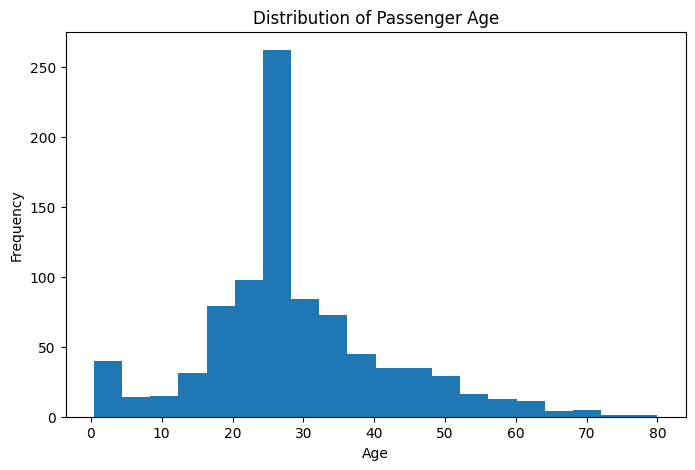

In [15]:
plt.figure(figsize=(8,5))

plt.hist(cleaned_df['age'], bins=20)

plt.title("Distribution of Passenger Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

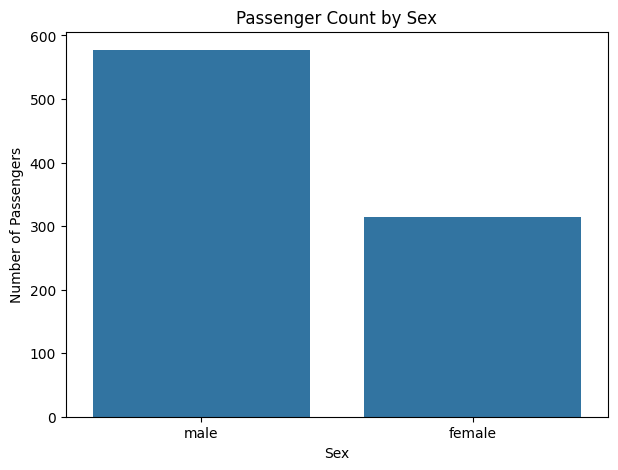

In [16]:
plt.figure(figsize=(7,5))

sns.countplot(data=cleaned_df, x='sex')

plt.title("Passenger Count by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Passengers")

plt.show()

In [17]:
encoded_df = pd.get_dummies(
    cleaned_df,
    columns=['sex', 'embarked'],
    drop_first=True,
    dtype=int
)

print(encoded_df.head())

   survived  pclass   age  sibsp  parch     fare  class    who  adult_male  \
0         0       3  22.0      1      0   7.2500  Third    man        True   
1         1       1  38.0      1      0  71.2833  First  woman       False   
2         1       3  26.0      0      0   7.9250  Third  woman       False   
3         1       1  35.0      1      0  53.1000  First  woman       False   
4         0       3  35.0      0      0   8.0500  Third    man        True   

   embark_town alive  alone  sex_male  embarked_Q  embarked_S  
0  Southampton    no  False         1           0           1  
1    Cherbourg   yes  False         0           0           0  
2  Southampton   yes   True         0           0           1  
3  Southampton   yes  False         0           0           1  
4  Southampton    no   True         1           0           1  


In [18]:
scaler = StandardScaler()

columns_to_scale = ['age', 'fare']

encoded_df[columns_to_scale] = scaler.fit_transform(
    encoded_df[columns_to_scale]
)

print(encoded_df.head())

   survived  pclass       age  sibsp  parch      fare  class    who  \
0         0       3 -0.565736      1      0 -0.502445  Third    man   
1         1       1  0.663861      1      0  0.786845  First  woman   
2         1       3 -0.258337      0      0 -0.488854  Third  woman   
3         1       1  0.433312      1      0  0.420730  First  woman   
4         0       3  0.433312      0      0 -0.486337  Third    man   

   adult_male  embark_town alive  alone  sex_male  embarked_Q  embarked_S  
0        True  Southampton    no  False         1           0           1  
1       False    Cherbourg   yes  False         0           0           0  
2       False  Southampton   yes   True         0           0           1  
3       False  Southampton   yes  False         0           0           1  
4        True  Southampton    no   True         1           0           1  


In [19]:
print("Final Dataset Shape:", encoded_df.shape)

print("Remaining Missing Values:")
print(encoded_df.isnull().sum().sum())

encoded_df.to_csv(
    'prepared_titanic_dataset.csv',
    index=False
)

print("Dataset saved successfully!")

Final Dataset Shape: (891, 15)
Remaining Missing Values:
0
Dataset saved successfully!


In [20]:
from google.colab import files

files.download('prepared_titanic_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>